In [1]:
!pip list

Package                 Version
----------------------- --------------------
absl-py                 2.5.0
asttokens               3.0.2
astunparse              1.6.3
certifi                 2026.7.22
cffi                    2.1.1
charset-normalizer      3.5.2
colorama                0.4.6
comm                    0.2.3
contourpy               1.3.3
cycler                  0.12.1
debugpy                 1.8.21
decorator               5.3.1
dill                    0.4.1
executing               2.2.1
fastjsonschema          2.21.2
flatbuffers             25.12.19
fonttools               4.63.0
gast                    0.7.0
google-pasta            0.2.0
grpcio                  1.84.0
h5py                    3.15.1
idna                    3.20
ipykernel               7.3.0
ipython                 9.15.0
ipython_pygments_lexers 1.1.1
jedi                    0.20.0
jupyter_client          8.9.1
jupyter_core            5.9.1
keras-nightly           3.16.0.dev2026100204
kiwisolver              

In [1]:
#Bring tensorflow
import tensorflow as tf
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu,True)

In [2]:
#Bringing in tesnorflow dataset for fashion minst
import tensorflow_datasets as  tdfs
#Bringing in matplotlib for viz stuff
from matplotlib import pyplot as plt

In [3]:
!pip install importlib_resources

import tensorflow as tf
import tensorflow_datasets as tfds
from matplotlib import pyplot as plt

#Configure GPU memory growth
gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
    tf.config.experimental.set_memory_growth(gpu, True)

# Load the dataset successfully
ds = tfds.load('fashion_mnist',split= 'train')
print("Enviorement initialized and dataset 'ds' loaded successfully! ")

C:\Users\Saba Siradze\PyCharmMiscProject\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Dl Completed...: 0 url [00:00, ? url/s]
Dl Size...: 0 MiB [00:00, ? MiB/s]

Dl Completed...:   0%|          | 0/1 [00:00<?, ? url/s]
Dl Size...: 0 MiB [00:00, ? MiB/s]

Dl Completed...:   0%|          | 0/2 [00:00<?, ? url/s]
Dl Size...: 0 MiB [00:00, ? MiB/s]

Dl Completed...:   0%|          | 0/3 [00:00<?, ? url/s]
Dl Size...: 0 MiB [00:00, ? MiB/s]

Dl Completed...:   0%|          | 0/4 [00:00<?, ? url/s]
Dl Size...: 0 MiB [00:00, ? MiB/s]

Dl Size...:   0%|          | 0/25 [00:01<?, ? MiB/s]

Dl Size...:   0%|          | 0/25 [00:01<?, ? MiB/s]

Dl Size...:   0%|          | 0/25 [00:01<?, ? MiB/s]

Dl Size...:   0%|          | 0/29 [00:01<?, ? MiB/s]

Dl Size...:   0%|          | 0/29 [00:01<?, ? MiB/s]

Dl Size...:   0%|          | 0/29 [00:01<?, ? MiB/s]

Dl Size...:   0%|          | 0/29 [00:01<?, ? MiB/s]

Extraction completed...:   0%|          | 0/1 [00:01<?, ? file/s]

Dl Size...:   0%|          | 0/29 [00:01<?, ? MiB/s]

Dl Size...:   0%|          | 0/29 [00:01<?, ? MiB/s]


Dataset fashion_mnist downloaded and prepared to C:\Users\Saba Siradze\tensorflow_datasets\fashion_mnist\3.0.1. Subsequent calls will reuse this data.
Enviorement initialized and dataset 'ds' loaded successfully! 


In [4]:
ds.as_numpy_iterator().next()['label']

np.int64(2)

## 2. Visualising data and building the dataset

In [5]:
# To do some data transformation we require the numpy library
import numpy as np

In [7]:
#Setup  connection aka iterator
dataiterator = ds.as_numpy_iterator()

In [8]:
#Getting data out of the pipeline
dataiterator.next()['image']

array([[[  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [ 18],
        [ 77],
        [227],
        [227],
        [208],
        [210],
        [225],
        [216],
        [ 85],
        [ 32],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0]],

       [[  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [ 61],
        [100],
        [ 97],
        [ 80],
        [ 57],
        [117],
        [227],
        [238],
        [115],
        [ 49],
        [ 78],
        [106],
        [108],
        [ 71],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0]],

       [[  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [  0],
        [ 81],
        [105],
        [ 80],
        [ 69],
      

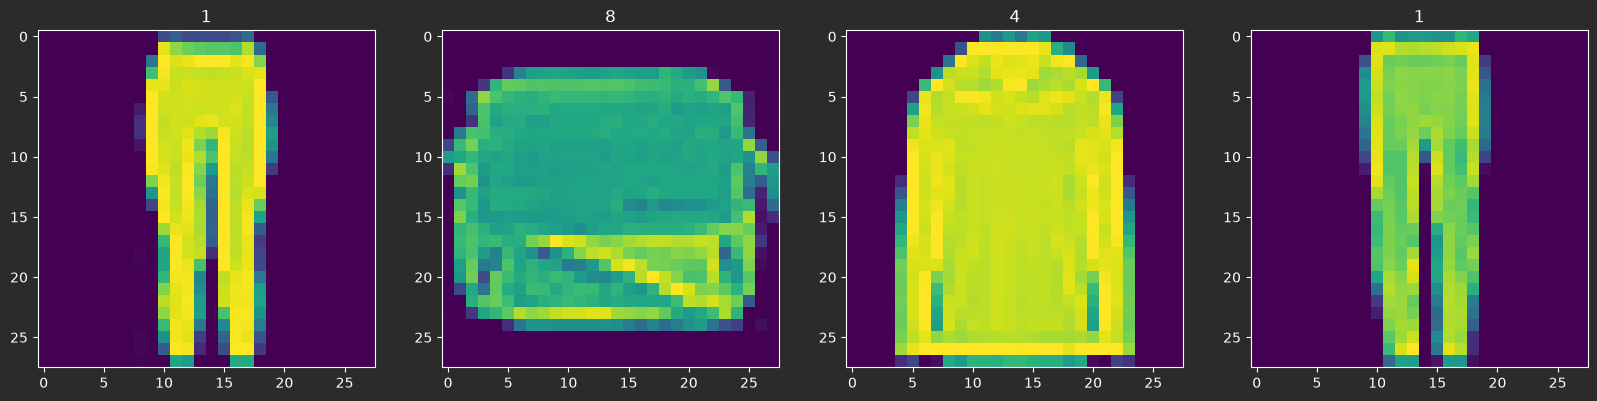

In [9]:
#Setup the subplot formatting
fig, ax = plt.subplots(ncols=4, figsize=(20,20))
#Loop four times and get images
for idx in range(4):
    # Grab an image and label
    sample = dataiterator.next()
    #Plot the image using a specific subplot
    ax[idx].imshow(sample['image'])
    #appending the image label as plot title
    ax[idx].title.set_text(sample['label'])


In [10]:
#Scale and return images only
def scale_images(data):
    image = data['image']
    return image/255

In [11]:
#Reload the dataset
ds = tfds.load('fashion_mnist', split= 'train')
ds = ds.map(scale_images)
ds = ds.cache()
ds = ds.shuffle(60000)
ds = ds.batch(128)
ds = ds.prefetch(64)

In [12]:
ds.as_numpy_iterator().next().shape

(128, 28, 28, 1)

## 3. Bulding a neural network